# 04 · Sleeve 1: pairs within a segment

Mean reversion between similar companies, re-selected each quarter on a trailing year (correlation, cointegration test and a balance-sheet similarity filter). Enter at |z| of 1.5-2, exit at 0.5, stop at 4, maximum 30 days. **Result: no reliable edge; excluded from the final book before the holdout.**

In [1]:
import json, warnings
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from shiplab import charts
from shiplab.config import DATA
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3, "display.width", 140)
R = DATA / "results"
perf = pd.read_csv(R / "performance_by_period.csv")
strat = pd.read_parquet(R / "strategy_returns.parquet")
bench = pd.read_parquet(R / "benchmark_returns.parquet")
dsr = json.load(open(R / "deflated_sharpe.json"))
def row(period, series="Strategy"):
    return perf[(perf.period == period) & (perf.series == series)].iloc[0]

In [2]:
from shiplab import metrics
grid = pd.read_parquet(R / "grid_returns.parquet")
picks = pd.read_csv(R / "walk_forward_picks.csv", index_col=0)
cols = [c for c in grid.columns if c.startswith("pairs")]
tab = pd.DataFrame({c: metrics.summary(grid[c].loc["2011":"2022"]) for c in cols}).T
display(tab[["ann_return", "ann_vol", "sharpe", "max_drawdown"]].round(3))
display(picks[["pairs"]].rename(columns={"pairs": "chosen for the year (prior data only)"}))

,ann_return,ann_vol,sharpe,max_drawdown
pairs|entry=1.5|corr=0.5,0.001,0.027,0.041,-0.065
pairs|entry=1.5|corr=0.6,-0.006,0.022,-0.275,-0.107
pairs|entry=2.0|corr=0.5,0.004,0.024,0.200,-0.043
pairs|entry=2.0|corr=0.6,0.001,0.020,0.083,-0.041


,chosen for the year (prior data only)
2014,NaN
2015,NaN
2016,pairs|entry=2.0|corr=0.6
2017,pairs|entry=2.0|corr=0.6
2018,pairs|entry=2.0|corr=0.5
2019,pairs|entry=2.0|corr=0.5
2020,pairs|entry=2.0|corr=0.5
2021,pairs|entry=1.5|corr=0.5
2022,pairs|entry=2.0|corr=0.5


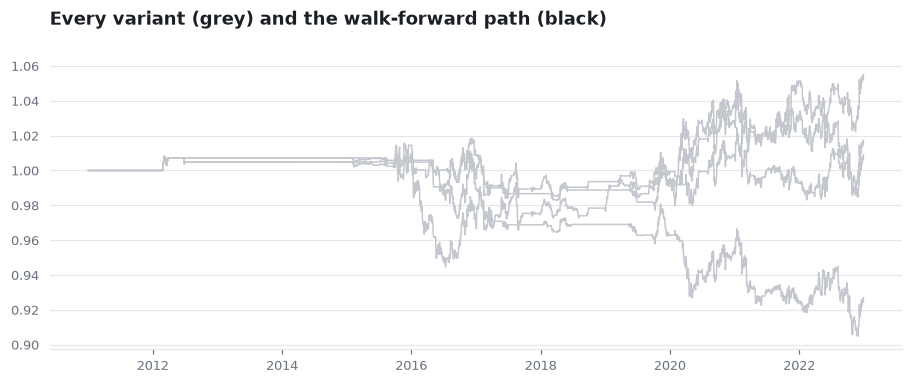

In [3]:
from shiplab import style
style.apply()
fig, ax = plt.subplots(figsize=(10, 3.4))
for c in cols:
    ax.plot((1 + grid[c].loc["2011":"2022"]).cumprod(), color="#C4C8CE", lw=1)
if "sleeve_pairs" in strat:
    s = strat["sleeve_pairs"].dropna()
    ax.plot((1 + s).cumprod(), color=style.INK, lw=2)
ax.set_title("Every variant (grey) and the walk-forward path (black)")
plt.show()